# Exercise 06.02 

Since the exercises 06.02, 06.03 and 06.04 share simmilar imports, data and ways of loading the data we have created a common.py file, that each exercise will fetch. 

In [1]:
from common import *

df = load_data()

# Loading and preparing data for training 
- i.e. defining predictors (AveRoooms) and splitting the training set into a 80/20 distribution


In [2]:

X = df[["AveRooms"]]
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


# Training the simple linear regression model on the training set only and printing the derived linear equation

In [3]:
model = LinearRegression()
model.fit(X_train, y_train)

intercept = model.intercept_
slope = model.coef_[0]
print(f"The linear equation is: y = {slope:.4f}x + {intercept:.4f}")


The linear equation is: y = 0.0768x + 1.6548


The linear equation says that according to this model the price of the house will increase with ≈8% per average room and a house with 0 rooms will have a price of $165.480 

# Predicting MedHouseVal with the same fitted model on both sets

In [7]:

y_pred= model.predict(X_test)


# calculating Mean Absolute Error (MAE), Mean Squared Error (MSE) and Coefficient of determination (R^2) for model

In [12]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
r2_training = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"MAE (test) = {mae:.4f}")
print(f"MSE (test) = {mse:.4f}")
print(f"R² (training) = {r2_training:.4f}")
print(f"R² (test) = {r2_test:.4f}")

MAE (test) = 0.8891
MSE (test) = 1.2923
R² (training) = 0.0251
R² (test) = 0.0138


# Scatterplot with the regression line


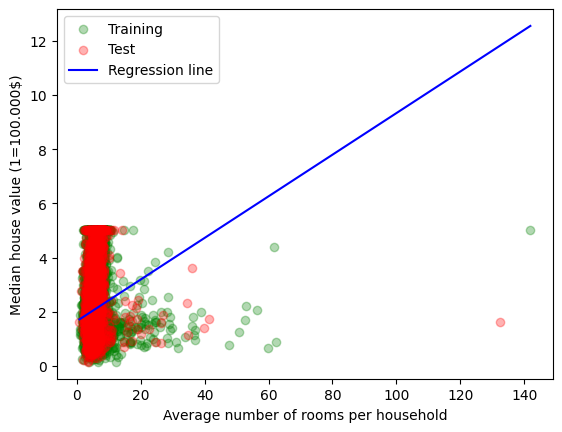

In [ ]:
plt.scatter(X_train, y_train, alpha=0.3, color="green", label="Training")
plt.scatter(X_test, y_test, alpha = 0.3, color="red", label="Test")
x_line = pd.DataFrame({"AveRooms": np.linspace(X["AveRooms"].min(), X["AveRooms"].max(), 100)})
plt.plot(x_line, model.predict(x_line), color="blue", label="Regression line")
plt.xlabel("Average number of rooms per household")
plt.ylabel("Median house value (1=100.000$)")
plt.legend()
plt.show()

# Questions: 

1: What is the R-squared score on both the training and test set? 
Answer:      
Training = 0.0251, test = 0.0138

2: Are the MAE and MSE values reasonable? What do these metrics tell you about the model's performance? 

Results:

MAE:   Training = 0.8973 test = 0.8891
MSE    Training = 1.3032 test = 1.2923

From both the MAE and MSE metrics it is quite clear, that the model is not that great (or rather totally  terrible) at predicting the median house value.  The MAE of both the training and test data says that on average the model is off by $89.000 which is quite remarkable as the mean house value is close to $200.000, and thus this model is off by around 40% if we use the average number of rooms per household as the predictor.

Considering MSE it is not looking much better. If we take the squareroot of the MSE (thus calculating the RMSE) we get a value of around 1.14, which suggests that the model is off by roughly $114.000, which is even worse. The (relatively) large difference between the MAE and RMSE also suggests that there are some very large errors in the dataset when using this model. 

3: Visualize the regression line on the scatter plot and interpret its fit. Does the linear relationship make sense for this dataset?

See scatter plot above for reference. 

From inspecting the scatterplot two observations especially comes to mind: 
1. There is a max-value for the Median house value of 5 per neighbourhood. I.e. if a value is equal to 5 ($500.000) it may actually be higher
2. There are some neighbourhoods with an absurdly high number of average rooms per household cause some error

If we directly infer from the scatterplot the linear model does not (viusally) match the regression line. 




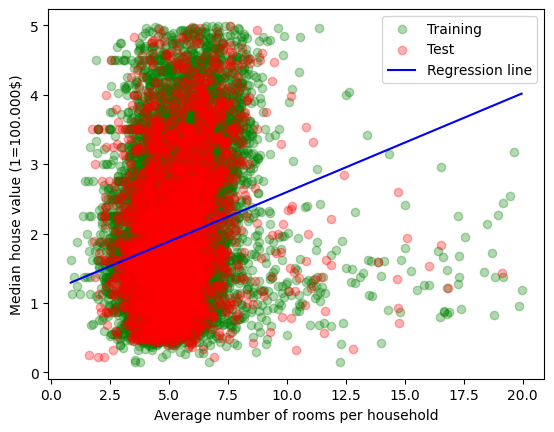

Training MAE: 0.7564
Training MSE: 0.9017
Test MAE:     0.7687
Test MSE:     0.9166


In [ ]:
# Load and prepare data
data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["MedHouseVal"] = data.target

# Keep only rows meeting both limits
df = df.loc[
    (df["MedHouseVal"] < 5) &
    (df["AveRooms"] <= 20)
].copy()

# Predictor and target
X = df[["AveRooms"]]
y = df["MedHouseVal"]

# Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train,y_train)

plt.scatter(X_train, y_train, alpha=0.3, color="green", label="Training")
plt.scatter(X_test, y_test, alpha = 0.3, color="red", label="Test")
x_line = pd.DataFrame({"AveRooms": np.linspace(X["AveRooms"].min(), X["AveRooms"].max(), 100)})
plt.plot(x_line, model.predict(x_line), color="blue", label="Regression line")
plt.xlabel("Average number of rooms per household")
plt.ylabel("Median house value (1=100.000$)")
plt.legend()
plt.show()

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print(f"Training MAE: {mean_absolute_error(y_train, y_train_pred):.4f}")
print(f"Training MSE: {mean_squared_error(y_train, y_train_pred):.4f}")
print(f"Test MAE:     {mean_absolute_error(y_test, y_test_pred):.4f}")
print(f"Test MSE:     {mean_squared_error(y_test, y_test_pred):.4f}")